In [ ]:
from dataclasses import dataclass
import numpy as np

TYPICAL_FIBER_LOSS_DB_PER_KM = {
    850: 2.50,    # multimode
    1310: 0.35,   # single-mode
    1550: 0.20,   # single-mode, lowest loss
}

In [ ]:
@dataclass
class OpticalLinkBudget:
    tx_power_dbm: float
    fiber_loss_db_per_km: float
    distance_km: float
    n_connectors: int = 2
    connector_loss_db: float = 0.5
    n_splices: int = 0
    splice_loss_db: float = 0.1
    system_margin_db: float = 3.0
    rx_sensitivity_dbm: float = -24.0

    def fiber_loss_total_db(self):
        return self.fiber_loss_db_per_km * self.distance_km

    def connector_loss_total_db(self):
        return self.n_connectors * self.connector_loss_db

    def splice_loss_total_db(self):
        return self.n_splices * self.splice_loss_db

    def total_loss_db(self):
        return (self.fiber_loss_total_db() + self.connector_loss_total_db()
                + self.splice_loss_total_db() + self.system_margin_db)

    def received_power_dbm(self):
        return self.tx_power_dbm - self.total_loss_db()

    def link_margin_db(self):
        return self.received_power_dbm() - self.rx_sensitivity_dbm

    def link_closes(self):
        return self.link_margin_db() >= 0

    def max_reach_km(self):
        fixed_loss_db = (self.connector_loss_total_db() + self.splice_loss_total_db()
                          + self.system_margin_db)
        budget_for_fiber_db = self.tx_power_dbm - self.rx_sensitivity_dbm - fixed_loss_db
        return max(budget_for_fiber_db / self.fiber_loss_db_per_km, 0.0)

    def received_power_vs_distance(self, distances_km):
        fixed_loss_db = (self.connector_loss_total_db() + self.splice_loss_total_db()
                          + self.system_margin_db)
        return self.tx_power_dbm - fixed_loss_db - self.fiber_loss_db_per_km * distances_km

In [ ]:
link = OpticalLinkBudget(
    tx_power_dbm=0.0,
    fiber_loss_db_per_km=TYPICAL_FIBER_LOSS_DB_PER_KM[1550],
    distance_km=80.0,
    n_connectors=2,
    n_splices=3,
)

print("Received power:", link.received_power_dbm(), "dBm")
print("Link margin:", link.link_margin_db(), "dB")
print("Link closes:", link.link_closes())
print("Max reach:", link.max_reach_km(), "km")

Received power: -20.3 dBm
Link margin: 3.6999999999999993 dB
Link closes: True
Max reach: 98.49999999999999 km


In [ ]:
import matplotlib.pyplot as plt

distances = np.linspace(0, 150, 500)
rx_power = link.received_power_vs_distance(distances)

In [ ]:
distances = np.linspace(0, 150, 500)
rx_power = link.received_power_vs_distance(distances)

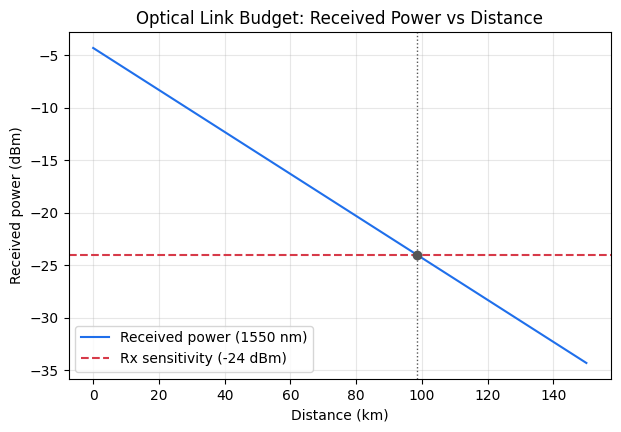

In [ ]:
reach = link.max_reach_km()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(distances, rx_power, label="Received power (1550 nm)", color="#1f6feb")
ax.axhline(link.rx_sensitivity_dbm, color="#d73a49", linestyle="--",
           label=f"Rx sensitivity ({link.rx_sensitivity_dbm:.0f} dBm)")
ax.axvline(reach, color="#555555", linestyle=":", linewidth=1)
ax.plot([reach], [link.rx_sensitivity_dbm], "o", color="#555555")

ax.set_xlabel("Distance (km)")
ax.set_ylabel("Received power (dBm)")
ax.set_title("Optical Link Budget: Received Power vs Distance")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

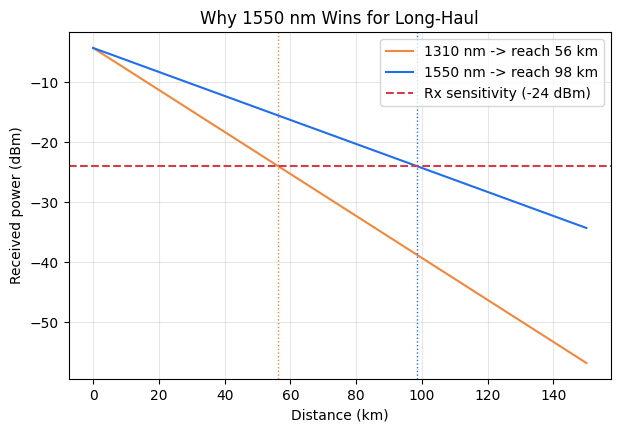

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {1310: "#f0883e", 1550: "#1f6feb"}

for wavelength in (1310, 1550):
    test_link = OpticalLinkBudget(
        tx_power_dbm=0.0,
        fiber_loss_db_per_km=TYPICAL_FIBER_LOSS_DB_PER_KM[wavelength],
        distance_km=100.0,
        n_connectors=2,
        n_splices=3,
    )
    rx = test_link.received_power_vs_distance(distances)
    reach = test_link.max_reach_km()
    ax.plot(distances, rx, color=colors[wavelength],
            label=f"{wavelength} nm -> reach {reach:.0f} km")
    ax.axvline(reach, color=colors[wavelength], linestyle=":", linewidth=1)

ax.axhline(-24.0, color="#d73a49", linestyle="--", label="Rx sensitivity (-24 dBm)")
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Received power (dBm)")
ax.set_title("Why 1550 nm Wins for Long-Haul")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()